In [34]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

from credit_risk_ai.data.load import load_train
from credit_risk_ai.data.clean import clean, drop_duplicate_rows
from credit_risk_ai.models.pipeline import build_logistic_regression, build_hist_gradient_boosting

N_SPLITS = 5
RANDOM_STATE = 42
TARGET = "SeriousDlqin2yrs"

In [35]:
data = clean(drop_duplicate_rows(load_train()))

X = data.drop(columns=[TARGET])
y = data[TARGET]

X.shape

(149391, 14)

In [36]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

valid = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    print(f"Fold {fold}: train = {len(train_idx)}, val = {len(val_idx)}, default_rate = {y.iloc[val_idx].mean():.3f}")
    valid.append(val_idx)
concat = np.concatenate(valid)
assert len(concat) == len(X)
assert len(np.unique(concat)) == len(X)

Fold 0: train = 119512, val = 29879, default_rate = 0.067
Fold 1: train = 119513, val = 29878, default_rate = 0.067
Fold 2: train = 119513, val = 29878, default_rate = 0.067
Fold 3: train = 119513, val = 29878, default_rate = 0.067
Fold 4: train = 119513, val = 29878, default_rate = 0.067


In [37]:
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}


In [38]:
builder = {
    "logistic_regression": build_logistic_regression,
    "hist_gradient_boosting": build_hist_gradient_boosting
}

results = {}
for name, build in builder.items():
    results[name] = cross_validate(build(), X, y, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)

## Step 5 · Summary: mean ± std over the 5 folds

- **Mean:** the expected score on new data.
- **Std:** how much the score changes from one fold to another, i.e. how much luck there is in a single split.

`cross_validate` returns the Brier score as a negative number (`neg_brier_score`, because sklearn treats "higher is better" for every score), so the sign is flipped back here. After flipping, lower Brier is better.

In [40]:
METRICS = ["roc_auc", "pr_auc", "brier"]

rows = []
for name, scores in results.items():
    row = {"model": name}
    for metric in METRICS:
        # "test_" = the validation fold (sklearn's name), one value per fold
        values = scores[f"test_{metric}"]
        if metric == "brier":
            values = -values  # neg_brier_score -> Brier score (lower is better)
        row[metric] = values.mean()
        row[f"{metric}_std"] = values.std()  # NumPy std: divides by n
    rows.append(row)

summary = pd.DataFrame(rows).set_index("model").round(4)
summary

,roc_auc,roc_auc_std,pr_auc,pr_auc_std,brier,brier_std
model,,,,,,
logistic_regression,0.8551,0.0040,0.3855,0.0111,0.0504,0.0005
hist_gradient_boosting,0.8649,0.0039,0.3977,0.0118,0.0492,0.0006


## Step 6: Per-fold Comparison



In [46]:
lr = results["logistic_regression"]["test_roc_auc"]
hgb = results["hist_gradient_boosting"]["test_roc_auc"]

#2 Per-fold difference fold i of HBG minus fold i of LR
diff = hgb - lr

per_fold = pd.DataFrame({
    "logistic_regression": lr,
    "hist_gradient_boosting": hgb,
    "difference": diff
})
per_fold.index.name = "fold"
per_fold.round(4)




,logistic_regression,hist_gradient_boosting,difference
fold,,,
0,0.8488,0.8588,0.0100
1,0.8542,0.8656,0.0114
2,0.8582,0.8671,0.0089
3,0.8539,0.8626,0.0087
4,0.8605,0.8703,0.0097


In [47]:
wins = (diff > 0).sum()

print(f"HGB wins: {wins} / {len(diff)} folds")
print(f"Mean difference: {diff.mean():+.4f}")
print(f"Std of difference: {diff.std():.4f}")
print(f"Smallest difference: {diff.min():+.4f}")

HGB wins: 5 / 5 folds
Mean difference: +0.0098
Std of difference: 0.0010
Smallest difference: +0.0087


## Step 7

In [48]:
gap_rows = []
for name, scores in results.items():
    train_auc = scores["train_roc_auc"].mean()
    val_auc = scores["test_roc_auc"].mean()

    gap = train_auc - val_auc

    row = {
        "model": name,
        "train": train_auc,
        "validation": val_auc,
        "gap": gap
    }
    gap_rows.append(row)
    gap_table = pd.DataFrame(gap_rows).set_index("model").round(4)
    display(gap_table)

,train,validation,gap
model,,,
logistic_regression,0.8553,0.8551,0.0002


,train,validation,gap
model,,,
logistic_regression,0.8553,0.8551,0.0002
hist_gradient_boosting,0.8858,0.8649,0.0209


## Step 8 ROC-AUC Curve

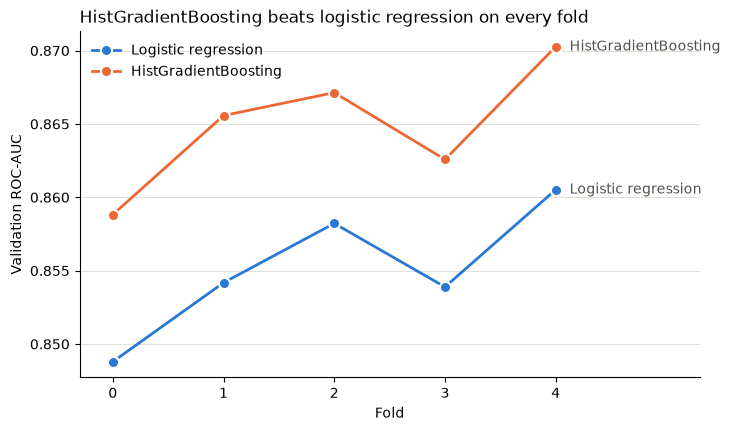

In [52]:
import matplotlib.pyplot as plt


LINES = [
    # (column in per_fold, label, color) - same colors as notebook 02
    ("logistic_regression", "Logistic regression", "#2a78d6"),
    ("hist_gradient_boosting", "HistGradientBoosting", "#eb6834"),
]
fig, ax = plt.subplots(figsize = (8, 4.5))
folds = per_fold.index
for column, label, color in LINES:
    scores = per_fold[column]
    ax.plot(folds, scores, color=color, linewidth=2, label=label, marker='o', markersize=8, markeredgecolor = "white", markeredgewidth=1.5)

    ax.annotate(label, xy=(folds[-1], scores.iloc[-1]), xytext=(10, 0), textcoords='offset points', va='center', color='#52514e')


ax.set_xticks(folds)
ax.set_xlim(-0.3, 5.3)
ax.set_xlabel("Fold")
ax.set_ylabel("Validation ROC-AUC")
ax.set_title("HistGradientBoosting beats logistic regression on every fold", loc='left')
ax.grid(axis='y', color="#e1e0d9", linewidth=0.8)
ax.spines[["top", 'right']].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

## Step 9 · Conclusions

**Setup:** 5-fold stratified CV on all 149,391 cleaned training rows (6.7% defaults in every fold).
Both models were scored on the same folds.

| Model | ROC-AUC | PR-AUC | Brier |
|---|---|---|---|
| Logistic regression | 0.8551 ± 0.0040 | 0.3855 ± 0.0111 | 0.0504 |
| HistGradientBoosting | **0.8649 ± 0.0039** | **0.3977 ± 0.0118** | **0.0492** |

**Findings**

1. **HistGradientBoosting is better, and the difference is real.** It wins on all three metrics and on
   5 of 5 folds (ROC-AUC +0.0098 on average, smallest gain +0.0087). The per-fold difference varies
   by only 0.0010, much less than each model's own spread (0.004), so the gain is not luck from the split.
2. **A single split is noisy.** Each model's score moves by about ±0.004 between folds. Notebook 02's
   single split (LR 0.8548, HGB 0.8625) falls inside the fold ranges but underestimated the gap
   (+0.0077 vs +0.0098). Small differences between future experiments must be checked with this CV,
   fold by fold, not with one split.
3. **Overfitting:** logistic regression has almost no gap between train and validation (0.0002), so it is
   limited by the model itself (straight-line boundaries), not by memorising. HistGradientBoosting has
   a gap of 0.021: mild overfitting, which leaves room for regularisation when tuning.

**Decision:** HistGradientBoosting becomes the main model; logistic regression stays as the simple,
interpretable baseline.

**Next steps** (all measured with the same `cv` and `scoring`):
- Feature engineering, checked with this CV.
- Tune HistGradientBoosting (`min_samples_leaf`, `l2_regularization`, `max_leaf_nodes`, `learning_rate`)
  with `RandomizedSearchCV`.
- Choose the decision threshold and check calibration using out-of-fold predictions.
